# Imports

In [35]:
import polars as pl
import matplotlib.pyplot as plt

# Loading data into data frame

In [24]:
crimes_df = pl.read_csv("../Crimes_-_2026_20260928.csv")

#separated by columns for better display
columns_1_5_crimes = crimes_df.select(["ID", "Case Number", "Date", "Block", "IUCR"]) 
columns_6_10_crimes = crimes_df.select(["Primary Type", "Description", "Location Description", "Arrest", "Domestic"])
columns_11_15_crimes = crimes_df.select(["Beat", "District", "Ward", "Community Area", "FBI Code"])
columns_16_19_crimes = crimes_df.select(["X Coordinate", "Y Coordinate", "Year", "Updated On"])
columns_20_22_crimes = crimes_df.select(["Latitude", "Longitude", "Location"])

print(columns_1_5_crimes)
print(columns_6_10_crimes)
print(columns_11_15_crimes)
print(columns_16_19_crimes)
print(columns_20_22_crimes)


shape: (167_474, 5)
┌──────────┬─────────────┬────────────────────────┬──────────────────────────┬──────┐
│ ID       ┆ Case Number ┆ Date                   ┆ Block                    ┆ IUCR │
│ ---      ┆ ---         ┆ ---                    ┆ ---                      ┆ ---  │
│ i64      ┆ str         ┆ str                    ┆ str                      ┆ str  │
╞══════════╪═════════════╪════════════════════════╪══════════════════════════╪══════╡
│ 14335596 ┆ JK423038    ┆ 09/20/2026 12:00:00 AM ┆ 017XX N WELLS ST         ┆ 1152 │
│ 14335903 ┆ JK423456    ┆ 09/20/2026 12:00:00 AM ┆ 022XX S KEDZIE AVE       ┆ 0760 │
│ 14333504 ┆ JK420554    ┆ 09/20/2026 12:00:00 AM ┆ 007XX W BRIAR PL         ┆ 0820 │
│ 14334121 ┆ JK421259    ┆ 09/20/2026 12:00:00 AM ┆ 062XX S CENTRAL PARK AVE ┆ 1320 │
│ 14334064 ┆ JK421123    ┆ 09/20/2026 12:00:00 AM ┆ 068XX S TALMAN AVE       ┆ 0910 │
│ …        ┆ …           ┆ …                      ┆ …                        ┆ …    │
│ 14071273 ┆ JK100639    ┆ 01/01/2

# Shape

In [8]:
print(crimes_df.shape)

(167474, 22)


167,474 crimes in the database with 22 columns of data connected to each crime

# Glimps

In [10]:
print(crimes_df.glimpse())

Rows: 167474
Columns: 22
$ ID                    <i64> 14335596, 14335903, 14333504, 14334121, 14334064, 14335587, 14334000, 14333109, 14334655, 14332977
$ Case Number           <str> 'JK423038', 'JK423456', 'JK420554', 'JK421259', 'JK421123', 'JK422926', 'JK420952', 'JK419790', 'JK422040', 'JK419735'
$ Date                  <str> '09/20/2026 12:00:00 AM', '09/20/2026 12:00:00 AM', '09/20/2026 12:00:00 AM', '09/20/2026 12:00:00 AM', '09/20/2026 12:00:00 AM', '09/20/2026 12:00:00 AM', '09/20/2026 12:00:00 AM', '09/20/2026 12:00:00 AM', '09/20/2026 12:00:00 AM', '09/20/2026 12:00:00 AM'
$ Block                 <str> '017XX N WELLS ST', '022XX S KEDZIE AVE', '007XX W BRIAR PL', '062XX S CENTRAL PARK AVE', '068XX S TALMAN AVE', '0000X E UNKNOWN AVE', '076XX S ESSEX AVE', '072XX S BENNETT AVE', '022XX N HALSTED ST', '038XX W AUGUSTA BLVD'
$ IUCR                  <str> '1152', '0760', '0820', '1320', '0910', '0281', '0460', '041A', '1320', '0486'
$ Primary Type          <str> 'DECEPTIVE PRAC

# Null Count

In [28]:
print(columns_1_5_crimes.null_count())
print(columns_6_10_crimes.null_count())
print(columns_11_15_crimes.null_count())
print(columns_16_19_crimes.null_count())
print(columns_20_22_crimes.null_count())

shape: (1, 5)
┌─────┬─────────────┬──────┬───────┬──────┐
│ ID  ┆ Case Number ┆ Date ┆ Block ┆ IUCR │
│ --- ┆ ---         ┆ ---  ┆ ---   ┆ ---  │
│ u32 ┆ u32         ┆ u32  ┆ u32   ┆ u32  │
╞═════╪═════════════╪══════╪═══════╪══════╡
│ 0   ┆ 0           ┆ 0    ┆ 0     ┆ 0    │
└─────┴─────────────┴──────┴───────┴──────┘
shape: (1, 5)
┌──────────────┬─────────────┬──────────────────────┬────────┬──────────┐
│ Primary Type ┆ Description ┆ Location Description ┆ Arrest ┆ Domestic │
│ ---          ┆ ---         ┆ ---                  ┆ ---    ┆ ---      │
│ u32          ┆ u32         ┆ u32                  ┆ u32    ┆ u32      │
╞══════════════╪═════════════╪══════════════════════╪════════╪══════════╡
│ 0            ┆ 0           ┆ 758                  ┆ 0      ┆ 0        │
└──────────────┴─────────────┴──────────────────────┴────────┴──────────┘
shape: (1, 5)
┌──────┬──────────┬──────┬────────────────┬──────────┐
│ Beat ┆ District ┆ Ward ┆ Community Area ┆ FBI Code │
│ ---  ┆ ---      ┆ --

Columns with null inputs are only related to location data (Location Description, Community Area, X Coordinate, Y Coordinate, Latitude/Longitude/Location).

# Describe

In [29]:
print(columns_1_5_crimes.describe())
print(columns_6_10_crimes.describe())
print(columns_11_15_crimes.describe())
print(columns_16_19_crimes.describe())
print(columns_20_22_crimes.describe())

shape: (9, 6)
┌────────────┬───────────────┬─────────────┬────────────────────────┬────────────────────┬────────┐
│ statistic  ┆ ID            ┆ Case Number ┆ Date                   ┆ Block              ┆ IUCR   │
│ ---        ┆ ---           ┆ ---         ┆ ---                    ┆ ---                ┆ ---    │
│ str        ┆ f64           ┆ str         ┆ str                    ┆ str                ┆ str    │
╞════════════╪═══════════════╪═════════════╪════════════════════════╪════════════════════╪════════╡
│ count      ┆ 167474.0      ┆ 167474      ┆ 167474                 ┆ 167474             ┆ 167474 │
│ null_count ┆ 0.0           ┆ 0           ┆ 0                      ┆ 0                  ┆ 0      │
│ mean       ┆ 1.4178e7      ┆ null        ┆ null                   ┆ null               ┆ null   │
│ std        ┆ 618808.403252 ┆ null        ┆ null                   ┆ null               ┆ null   │
│ min        ┆ 29000.0       ┆ HK572868    ┆ 01/01/2026 01:00:00 AM ┆ 0000X E 100TH PL

All crimes are from start of 2026 to September 20th 2026.

# Anomalies

* 304 crimes reported don't have a location associated with the crime. These crimes will be dropped from the table <br>

# Distributions

shape: (31, 2)
┌─────────────────────────────────┬───────┐
│ Primary Type                    ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ THEFT                           ┆ 36122 │
│ CONCEALED CARRY LICENSE VIOLAT… ┆ 183   │
│ OTHER NARCOTIC VIOLATION        ┆ 5     │
│ GAMBLING                        ┆ 13    │
│ ARSON                           ┆ 278   │
│ …                               ┆ …     │
│ INTIMIDATION                    ┆ 180   │
│ INTERFERENCE WITH PUBLIC OFFIC… ┆ 746   │
│ OBSCENITY                       ┆ 41    │
│ BATTERY                         ┆ 30875 │
│ ROBBERY                         ┆ 3433  │
└─────────────────────────────────┴───────┘
shape: (1, 1)
┌────────┐
│ count  │
│ ---    │
│ u32    │
╞════════╡
│ 167474 │
└────────┘
shape: (5, 2)
┌─────────────────────┬───────┐
│ Primary Type        ┆ count │
│ ---                 ┆ ---   │
│ str                 ┆ u32   │
╞═══

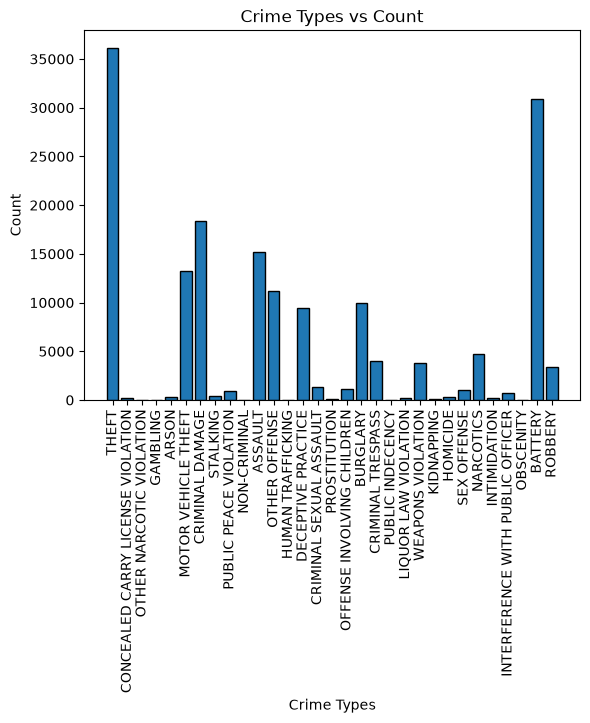

In [45]:
primary_type_col = columns_6_10_crimes["Primary Type"]
primary_type_col = primary_type_col.value_counts()#.sort("count")
print(primary_type_col)
print(primary_type_col.select(pl.sum("count")))
print(primary_type_col.top_k(5, by="count"))
print(primary_type_col.top_k(5, by="count").select(pl.sum("count")))
plt.bar(primary_type_col["Primary Type"].to_numpy(), primary_type_col["count"].to_numpy(), edgecolor="black")
plt.xlabel("Crime Types")
plt.ylabel("Count")
plt.title("Crime Types vs Count")
plt.xticks(rotation=90)
plt.show()

The Crime Types vs Count bar chart is showing the different type of crimes identified by the city of Chicago and their frequency in the 2026 crimes database. There are 167474 crimes divided among 31 different types of crimes. The majority (67.93%) of crimes are classified as one of the top 5 crime types (theft, battery, criminal damage, assault, and motor vehicle theft). Leaving the remanding 26 groups to account for 32.07% of the remaining crimes.

shape: (51, 2)
┌──────┬───────┐
│ Ward ┆ count │
│ ---  ┆ ---   │
│ i64  ┆ u32   │
╞══════╪═══════╡
│ 0    ┆ 267   │
│ 38   ┆ 1433  │
│ 39   ┆ 1499  │
│ 23   ┆ 1505  │
│ 19   ┆ 1620  │
│ …    ┆ …     │
│ 20   ┆ 5740  │
│ 42   ┆ 5871  │
│ 6    ┆ 6271  │
│ 28   ┆ 7438  │
│ 27   ┆ 7789  │
└──────┴───────┘
shape: (1, 1)
┌────────┐
│ count  │
│ ---    │
│ u32    │
╞════════╡
│ 167474 │
└────────┘
shape: (5, 2)
┌──────┬───────┐
│ Ward ┆ count │
│ ---  ┆ ---   │
│ i64  ┆ u32   │
╞══════╪═══════╡
│ 27   ┆ 7789  │
│ 28   ┆ 7438  │
│ 6    ┆ 6271  │
│ 42   ┆ 5871  │
│ 20   ┆ 5740  │
└──────┴───────┘
shape: (1, 1)
┌───────┐
│ count │
│ ---   │
│ u32   │
╞═══════╡
│ 33109 │
└───────┘


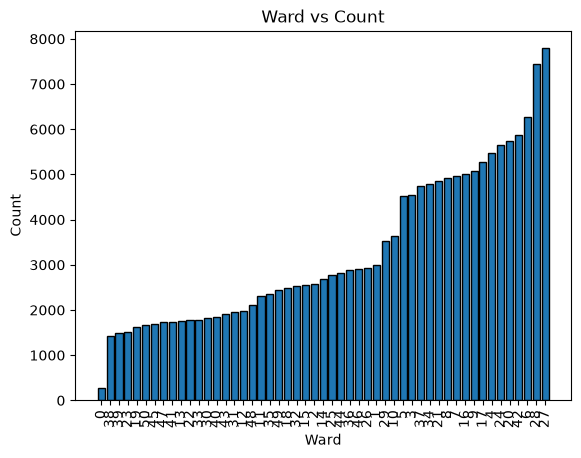

In [56]:
ward_col = columns_11_15_crimes["Ward"]
ward_col = ward_col.value_counts().sort("count")
print(ward_col)
print(ward_col.select(pl.sum("count")))
print(ward_col.top_k(5, by="count"))
print(ward_col.top_k(5, by="count").select(pl.sum("count")))
plt.bar(ward_col["Ward"].cast(pl.String).to_numpy(), ward_col["count"].to_numpy(), edgecolor="black")
plt.xlabel("Ward")
plt.ylabel("Count")
plt.title("Ward vs Count")
plt.xticks(rotation=90)
plt.show()

The Ward vs Coount bar chart displays the wards in Chicago and the amount of crimes reported within them. In total there are 167,474 crimes divided among 51 wards. Unlike the Crime Type vs Count bar chart and other charts seen in out other datasets the jumps between wards isn't as drastic. The bar chart shows a gradual progression in wards with higher crimes.